# 05e — d1 architecture exploration

EfficientNet-B0 is the reference, not a predetermined winner. Compare its saved
six-epoch records with independently configured pretrained DenseNet121 and
ConvNeXt-Tiny on the same inner validation patients. All eight new fits are a
maximum target, not a completion promise. A short trial cannot eliminate a
slower family. Outer fold 0 and the reserved test remain excluded.

The notebook defaults to reading executed results. Training, when explicitly
enabled, calls the shared runner and existing training loop. No independent
training implementation appears here.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_architecture import load_config, prepare_architecture_pilot, run_architecture_pilot
from melanoma_detection.image_evaluation import load_historical_pilot, load_architecture_outputs, metric_table, curve_tables, sha256
from melanoma_detection.image_reporting import (plot_learning_curves, plot_training_losses,
    plot_roc_precision_recall, plot_confusion_matrices, plot_resource_comparison,
    plot_raw_reliability, plot_augmentation_preview, save_figure)

TRAIN_ARCHITECTURES = False
config = load_config(PROJECT_ROOT / "configs/image_architecture_pilot.yaml")
run_dir = PROJECT_ROOT / config["run"]["output_dir"] / config["run"]["run_id"]
historical = load_historical_pilot(PROJECT_ROOT)
if TRAIN_ARCHITECTURES:
    prepared = prepare_architecture_pilot(PROJECT_ROOT, config, audit_images=True)
    summary = run_architecture_pilot(PROJECT_ROOT, config, prepared=prepared, resume=True, device="cuda")
else:
    summary_path = run_dir / "summary.json"
    if not summary_path.is_file():
        raise FileNotFoundError("Prepare/run the shared architecture CLI first; this notebook does not fabricate results.")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
bundle = load_architecture_outputs(PROJECT_ROOT, summary)
predictions, matched, history = bundle["predictions"], bundle["matched_predictions"], bundle["histories"]
all_records = [*summary.get("b0_reference", []), *summary.get("recipes", [])]
epochs = {record["pipeline_id"]: record.get("best_epoch") for record in all_records}
figures_dir, tables_dir = run_dir / "figures", run_dir / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Run:", summary["run_id"], "| status:", summary["status"], "| training enabled:", TRAIN_ARCHITECTURES)
print("Matched completed slots:", summary["matched_recipe_slots"])
print("Unmatched completed trials:", summary["unmatched_completed_trials"])
display(Markdown(summary["recommendation"]))


Run: architecture_pilot_3h_v1 | status: complete | training enabled: False
Matched completed slots: ['low_none', 'low_sqrt', 'high_none', 'high_sqrt']
Unmatched completed trials: []


Complete paused trials, then independently validate every family with longer training and three inner folds; short-pilot scores cannot eliminate a slower family.

## Controlled preparation, recipes and completion ledger

The same patient memberships, RGB whole-image 224-pixel bilinear preparation,
weak flips/rotation and unchanged preprocessing apply to every family. ImageNet
normalisation remains fixed. B0/DenseNet freeze BatchNorm statistics and affine
parameters; ConvNeXt preserves its native LayerNorm and trains it during full
fine-tuning. Each new output uses explicit dropout 0.2 and one logit.

Each family has its own lower/higher backbone learning rates crossed with
unweighted or fitting-only square-root positive weighting. Effective batch is
64. Use one classifier-only warmup and a fixed 30-epoch schedule, executing six
epochs with no early stopping. The selected checkpoint is actual highest AP;
exact ties retain the earlier epoch.

Finish DenseNet/ConvNeXt in matched pairs before starting the next slot. Paused
trials cannot lose a comparison. At most 50 minutes are available for training,
subject to the overall session deadline and reporting reserve.


In [2]:
ledger_rows = []
for record in all_records:
    ledger_rows.append({"pipeline_id": record["pipeline_id"], "family": record["architecture"],
        "recipe_slot": record["recipe_slot"], "status": record["status"],
        "completed_epochs": record.get("completed_epochs"), "selected_epoch": record.get("best_epoch"),
        "backbone_lr": record.get("backbone_lr"), "loss_weight": record.get("loss_weight"),
        "matched_comparison": record["recipe_slot"] in summary["matched_recipe_slots"]})
ledger = pd.DataFrame(ledger_rows)
ledger.to_csv(tables_dir / "completion_ledger.csv", index=False)
display(ledger)
display(pd.DataFrame(summary.get("runtime_estimates", {})).T)
print("Ordinary validation: deterministic | calibrated scores: unavailable | tuned thresholds: deferred")


,pipeline_id,family,recipe_slot,status,completed_epochs,selected_epoch,backbone_lr,loss_weight,matched_comparison
0,efficientnet_b0/low_none,efficientnet_b0,low_none,complete,6,5,NaN,NaN,True
1,efficientnet_b0/low_sqrt,efficientnet_b0,low_sqrt,complete,6,6,NaN,NaN,True
2,efficientnet_b0/high_none,efficientnet_b0,high_none,complete,6,4,NaN,NaN,True
3,efficientnet_b0/high_sqrt,efficientnet_b0,high_sqrt,complete,6,6,NaN,NaN,True
4,densenet121/low_none,densenet121,low_none,complete,6,2,0.00003,none,True
5,convnext_tiny/low_none,convnext_tiny,low_none,complete,6,6,0.00001,none,True
6,densenet121/low_sqrt,densenet121,low_sqrt,complete,6,6,0.00003,sqrt_ratio,True
7,convnext_tiny/low_sqrt,convnext_tiny,low_sqrt,complete,6,6,0.00001,sqrt_ratio,True
8,densenet121/high_none,densenet121,high_none,complete,6,4,0.00010,none,True
9,convnext_tiny/high_none,convnext_tiny,high_none,complete,6,6,0.00003,none,True


,measured_mean_epoch_seconds,measured_max_epoch_seconds,measured_epochs,peak_allocated_memory_bytes
densenet121,43.079217,46.140481,24.0,2.352355e+09
convnext_tiny,45.313949,55.085114,24.0,1.587335e+09


Ordinary validation: deterministic | calibrated scores: unavailable | tuned thresholds: deferred


Fitting-only weak-preparation preview. The existing rotation can create black
corners and clip peripheral pixels; the limited preview does not certify every
lesion. Stronger augmentation, hair removal and lighting correction are deferred.


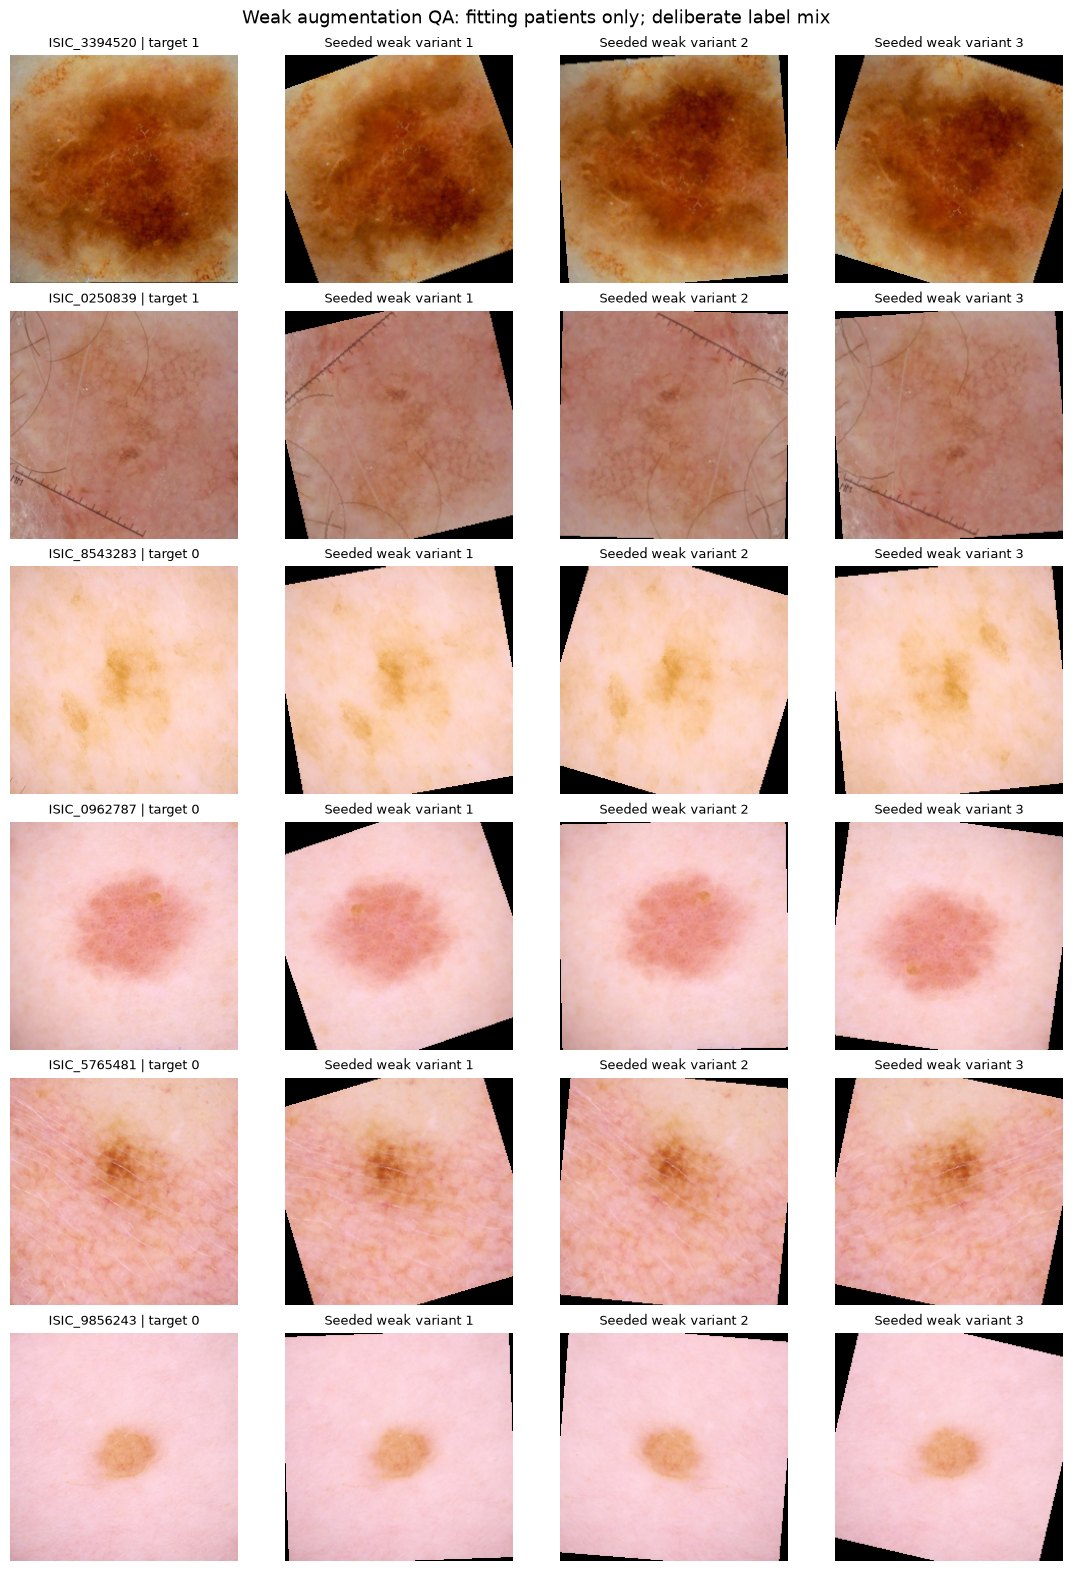

In [3]:
preview = plot_augmentation_preview(historical["fitting"], config["model"])
save_figure(preview, figures_dir / "weak_augmentation_preview.png", dpi=130)
plt.show()


## Executed learning trajectories

The panels below use committed epochs only, including paused trials explicitly
marked in their legends. Hollow rings mark highest-AP epochs so far.
Weighted and unweighted fitting losses represent different objectives and are
shown separately; validation log loss and Brier are unweighted for all trials.
Checkpoints from a six-epoch cap remain exploratory duration choices.


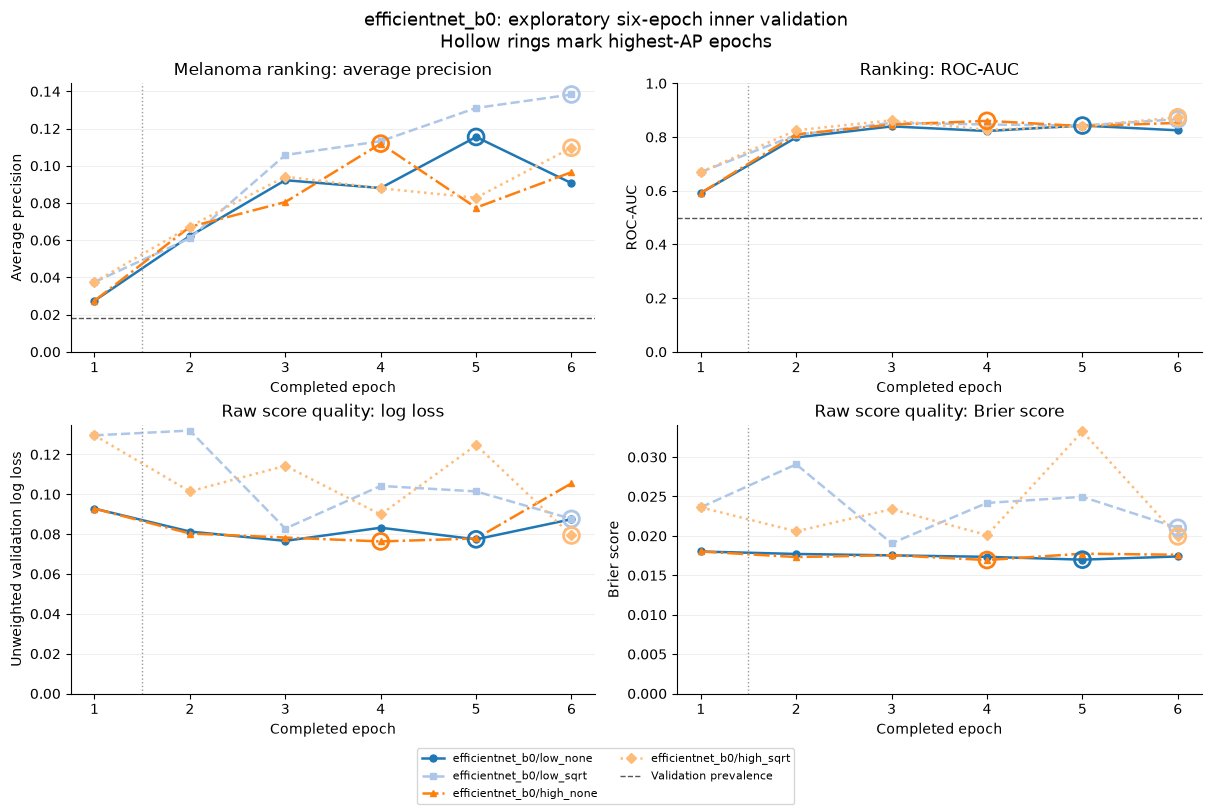

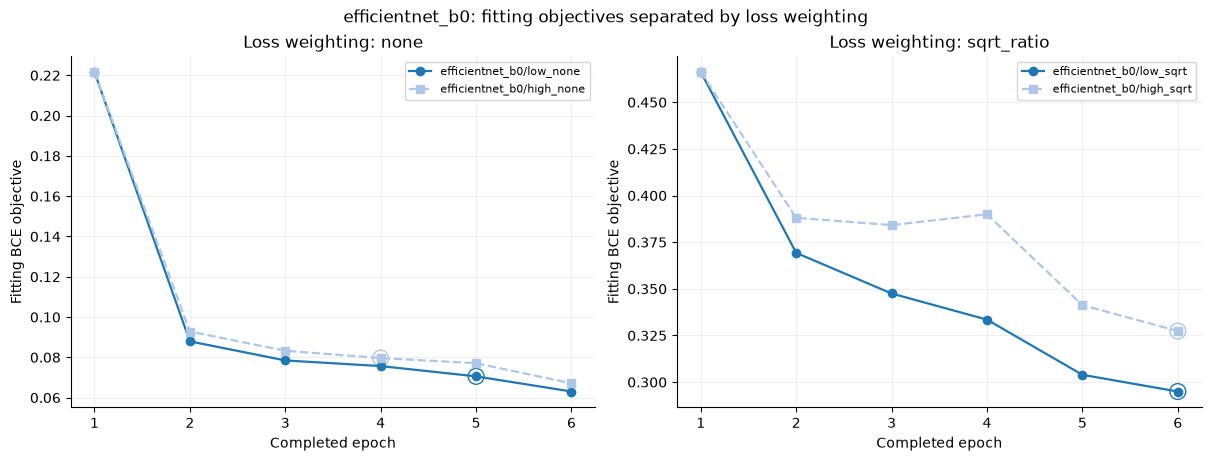

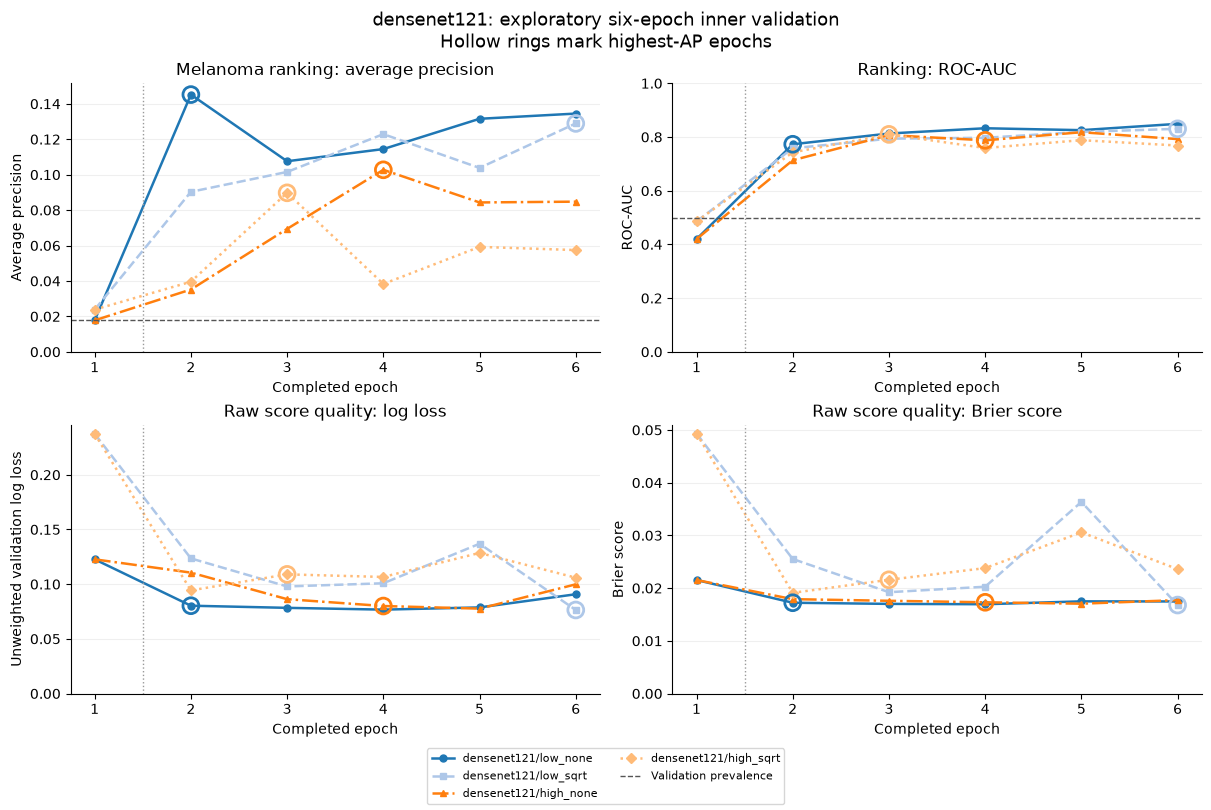

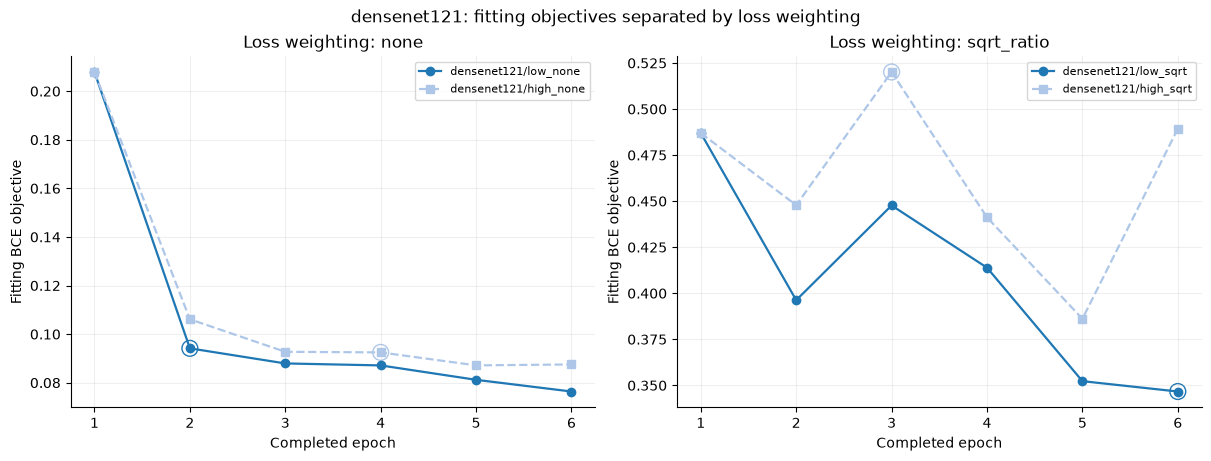

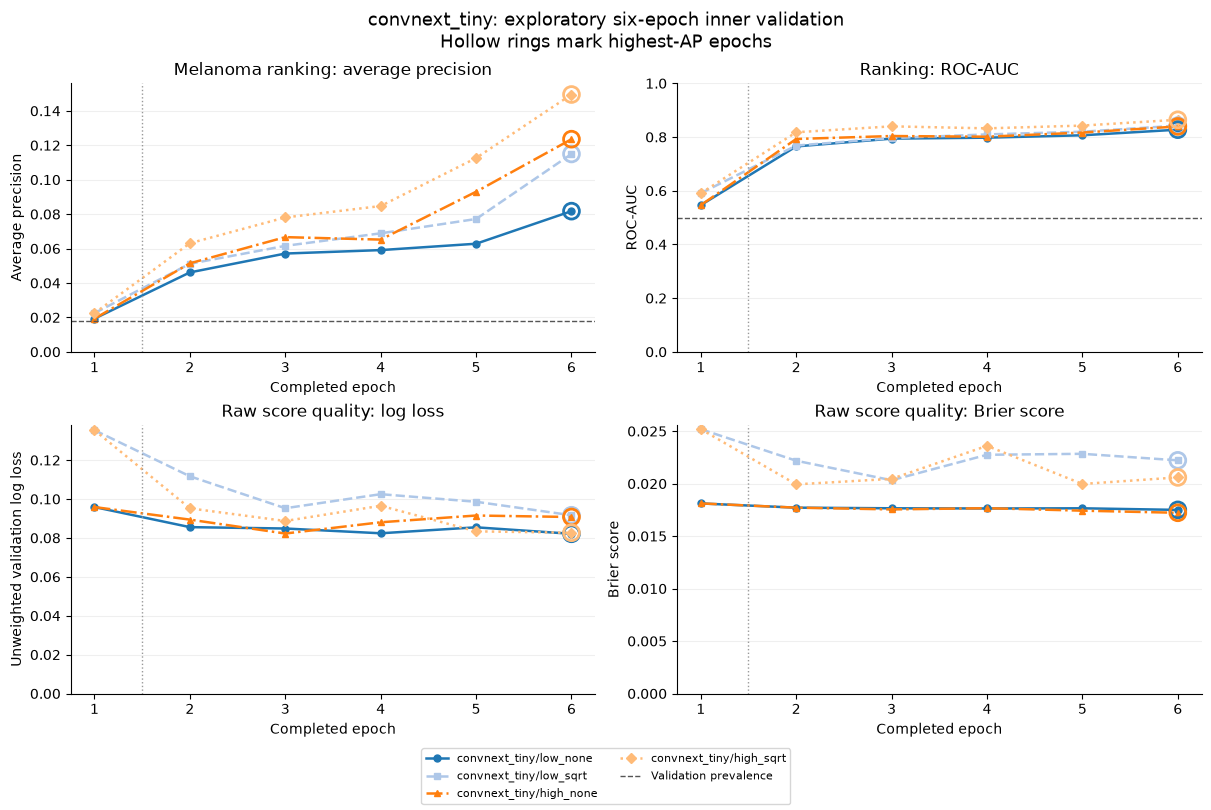

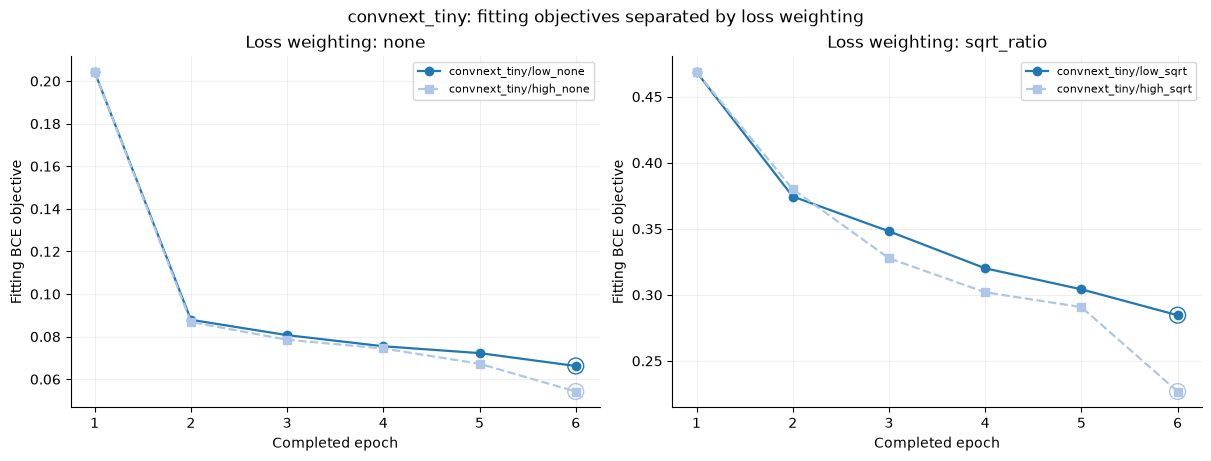

In [4]:
if not history.empty:
    for family, family_history in history.groupby("architecture", sort=False):
        fig = plot_learning_curves(family_history, historical["validation"].target.mean(),
            f"{family}: exploratory six-epoch inner validation")
        save_figure(fig, figures_dir / f"{family}_learning_curves.png")
        plt.show()
        loss = plot_training_losses(family_history, title=f"{family}: fitting objectives separated by loss weighting")
        save_figure(loss, figures_dir / f"{family}_training_loss.png")
        plt.show()
else:
    print("No completed trial histories available; no curves fabricated.")


## Matched family comparison

Only recipe slots completed for **all three families** enter the comparative
tables and plots. All use matching validation images and patients. AP is primary;
ROC-AUC and actual precision–recall/ROC curves describe ranking. Measured epoch
time excludes weight-download/setup overhead. Peak memory is measured allocated
GPU memory, not total device usage. These are early learning results, not a
final architecture selection.


,pipeline_id,selected_epoch,average_precision,roc_auc,log_loss,brier,n_images,n_patients
0,efficientnet_b0/low_none,5,0.1155,0.8426,0.0774,0.0170,1834,113
1,efficientnet_b0/low_sqrt,6,0.1383,0.8663,0.0876,0.0210,1834,113
2,efficientnet_b0/high_none,4,0.1119,0.8602,0.0763,0.0169,1834,113
3,efficientnet_b0/high_sqrt,6,0.1097,0.8734,0.0793,0.0199,1834,113
4,densenet121/low_none,2,0.1452,0.7730,0.0803,0.0172,1834,113
5,convnext_tiny/low_none,6,0.0817,0.8273,0.0821,0.0175,1834,113
6,densenet121/low_sqrt,6,0.1289,0.8305,0.0764,0.0168,1834,113
7,convnext_tiny/low_sqrt,6,0.1150,0.8423,0.0917,0.0222,1834,113
8,densenet121/high_none,4,0.1027,0.7876,0.0800,0.0173,1834,113
9,convnext_tiny/high_none,6,0.1235,0.8393,0.0908,0.0172,1834,113


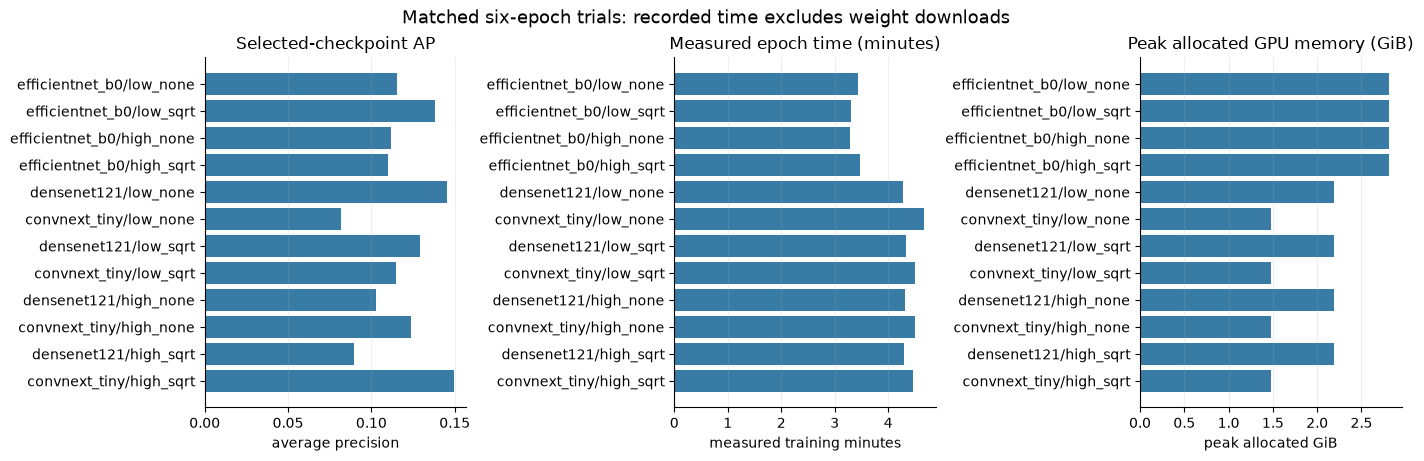

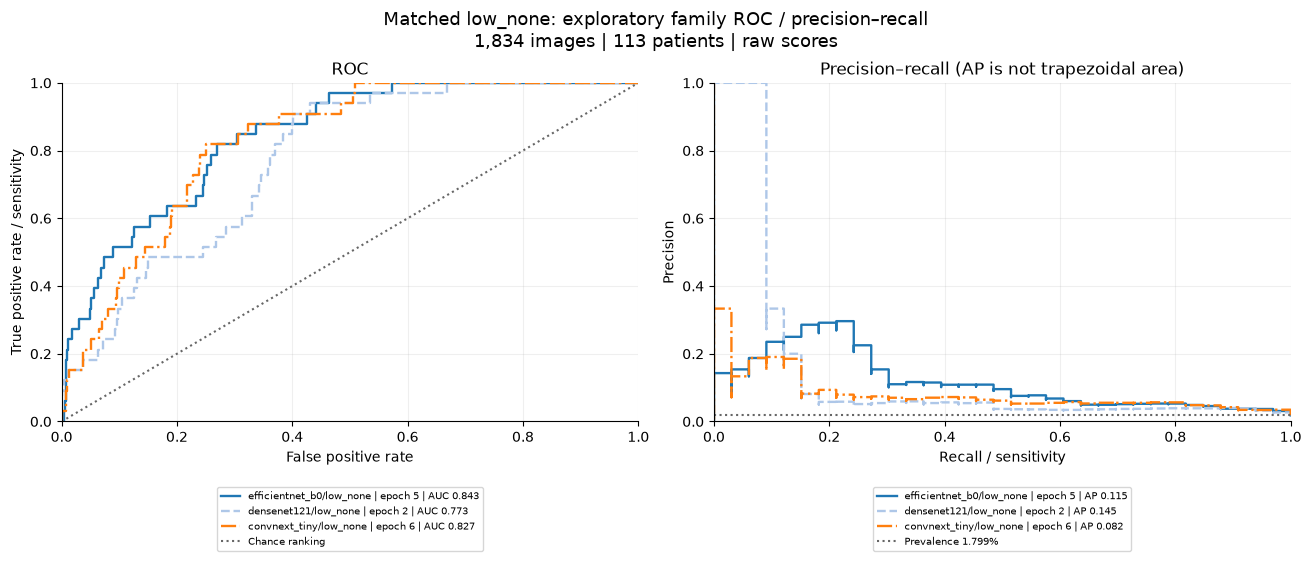

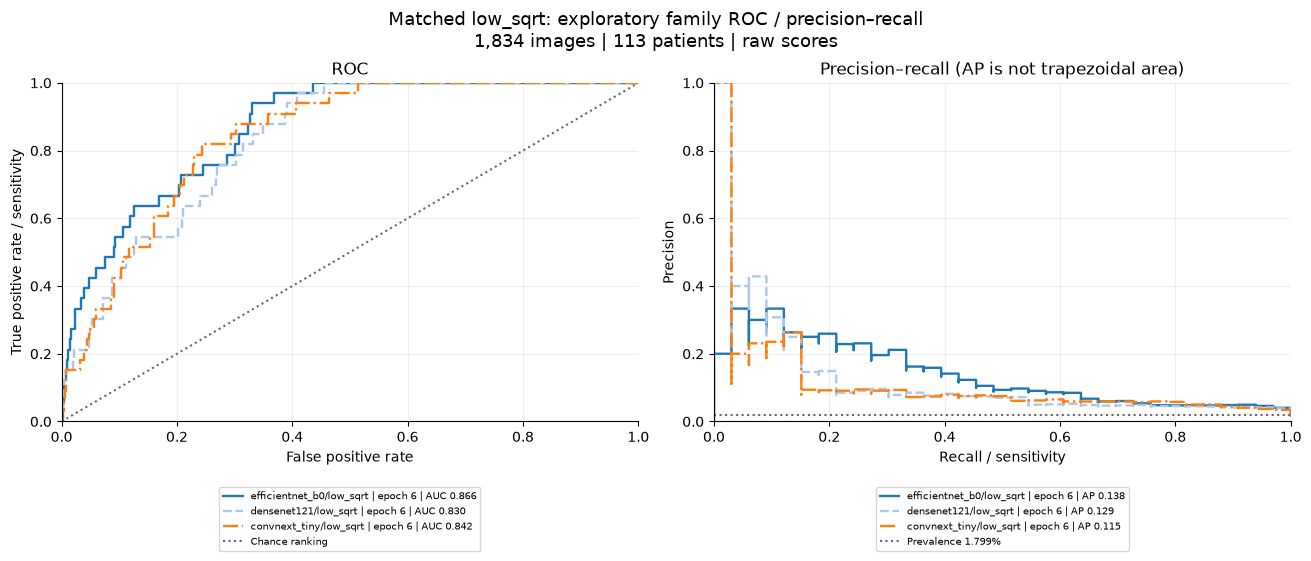

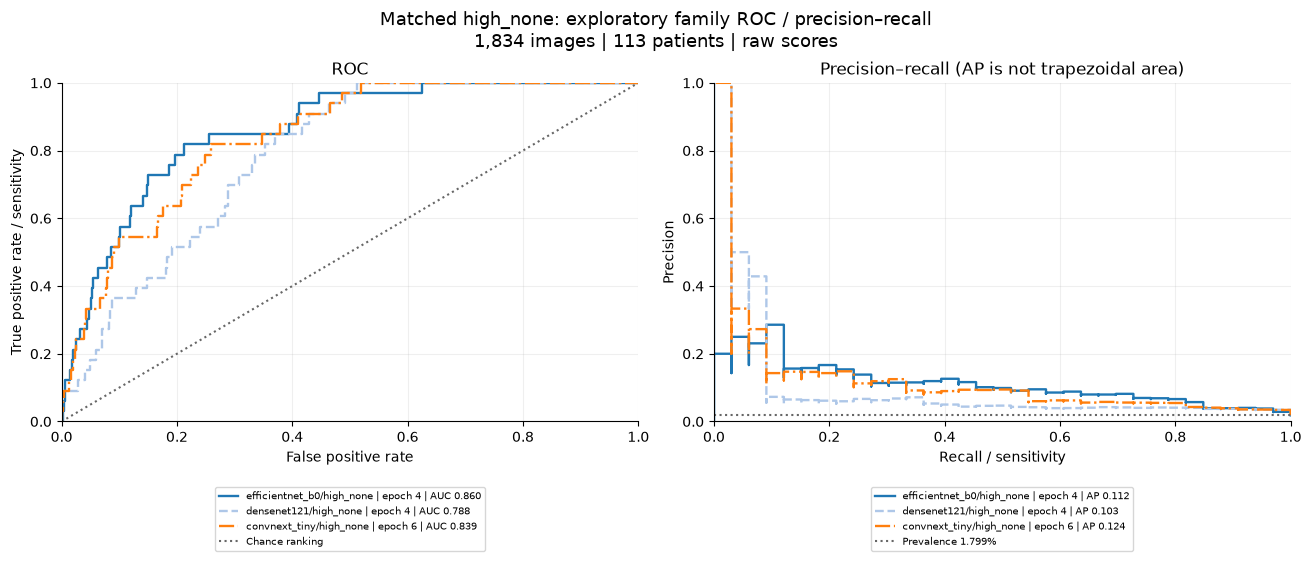

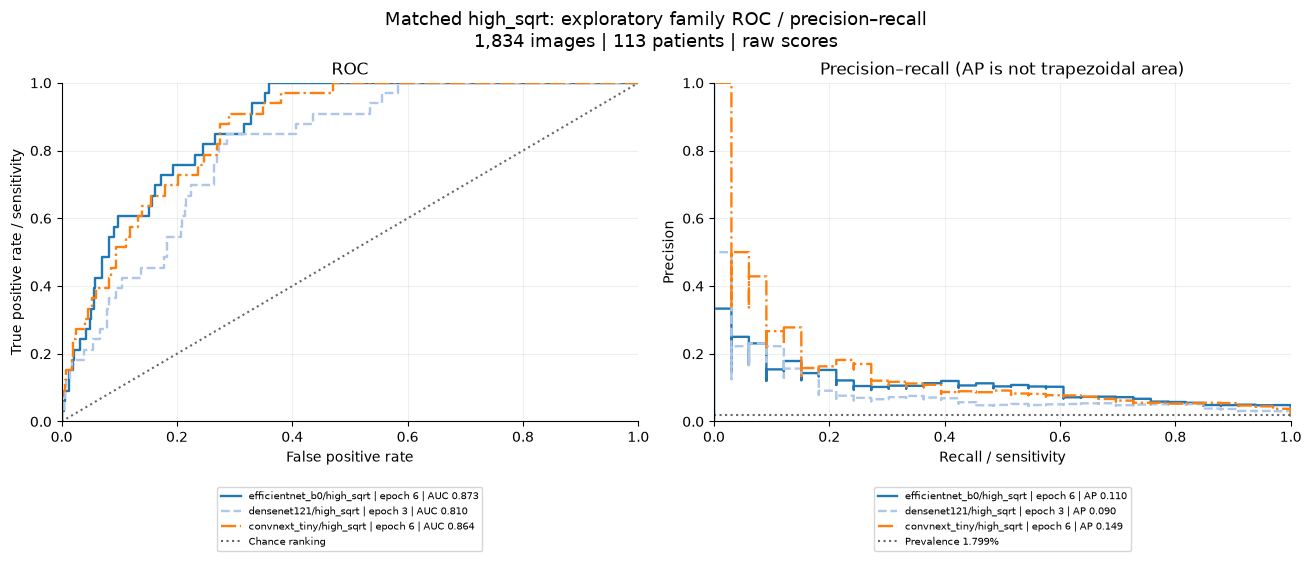

In [5]:
if matched:
    metrics = metric_table(matched, threshold=.5, epochs=epochs)
    metrics.to_csv(tables_dir / "matched_metrics_raw_threshold_0_5.csv", index=False)
    display(metrics[["pipeline_id", "selected_epoch", "average_precision", "roc_auc", "log_loss", "brier",
        "n_images", "n_patients"]].style.format({key: "{:.4f}" for key in
        ["average_precision", "roc_auc", "log_loss", "brier"]}))
    matched_history = history.loc[history.pipeline_id.isin(matched)]
    resource = plot_resource_comparison(matched_history, metrics)
    save_figure(resource, figures_dir / "matched_performance_time_memory.png")
    plt.show()
    for slot in summary["matched_recipe_slots"]:
        paired = {key: frame for key, frame in matched.items() if frame.recipe_slot.iloc[0] == slot}
        curves = plot_roc_precision_recall(paired, epochs=epochs,
            title=f"Matched {slot}: exploratory family ROC / precision–recall")
        save_figure(curves, figures_dir / f"{slot}_roc_precision_recall.png")
        plt.show()
        for identity, frame in paired.items():
            for name, table in curve_tables(frame.target, frame.base_probability).items():
                if isinstance(table, pd.DataFrame):
                    table.to_csv(tables_dir / f"{identity.replace('/', '__')}_{name}.csv", index=False)
else:
    print("No matched DenseNet/ConvNeXt/B0 slot completed; no family ranking reported.")


## Fixed-threshold exploratory classification and raw calibration

Flag scores `>= 0.5` using raw base probabilities. The cutoff is declared, not
fitted to validation labels. Confusion plots show counts and percentages within
each true class; report F1, precision, recall/sensitivity and specificity with
the cutoff, checkpoint and support. Undefined precision remains missing.

Reliability plots are descriptive raw-score checks, not fitted calibration or
clinical risk. The academic 80%-recall cutoff awaits training-only OOF scores.


,pipeline_id,selected_epoch,threshold,score_type,TP,FP,TN,FN,precision,recall,sensitivity,specificity,f1
0,efficientnet_b0/low_none,5,0.500000,raw_base_probability,0,1,1800,33,0.0000,0.0000,0.0000,0.9994,0.0000
1,efficientnet_b0/low_sqrt,6,0.500000,raw_base_probability,4,14,1787,29,0.2222,0.1212,0.1212,0.9922,0.1569
2,efficientnet_b0/high_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
3,efficientnet_b0/high_sqrt,6,0.500000,raw_base_probability,3,14,1787,30,0.1765,0.0909,0.0909,0.9922,0.1200
4,densenet121/low_none,2,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
5,convnext_tiny/low_none,6,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
6,densenet121/low_sqrt,6,0.500000,raw_base_probability,1,0,1801,32,1.0000,0.0303,0.0303,1.0000,0.0588
7,convnext_tiny/low_sqrt,6,0.500000,raw_base_probability,3,12,1789,30,0.2000,0.0909,0.0909,0.9933,0.1250
8,densenet121/high_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
9,convnext_tiny/high_none,6,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000


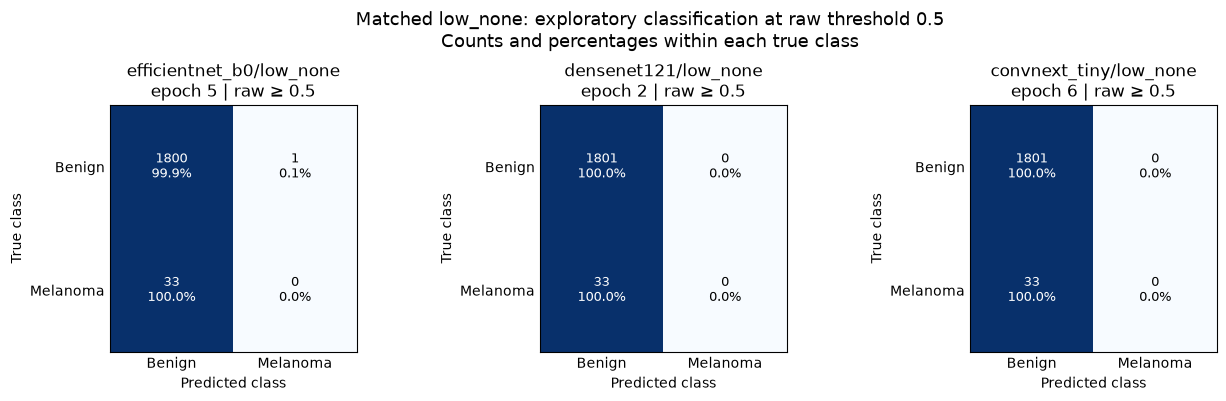

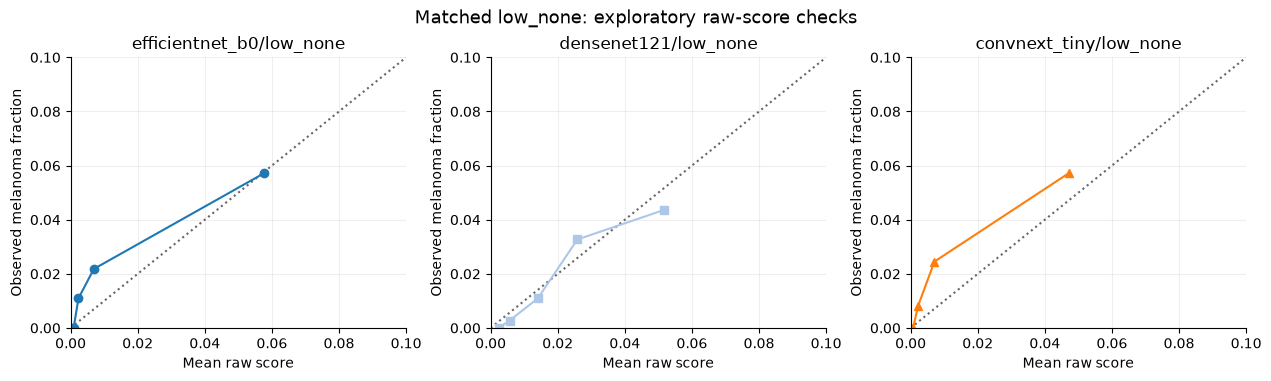

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.000285,0.000000,0.000052,0.000517,47,efficientnet_b0/low_none
1,2,367,0,0.000890,0.000000,0.000518,0.001391,64,efficientnet_b0/low_none
2,3,366,4,0.002341,0.010929,0.001393,0.003656,77,efficientnet_b0/low_none
3,4,367,8,0.006916,0.021798,0.003667,0.012304,88,efficientnet_b0/low_none
4,5,367,21,0.057722,0.057221,0.012340,0.528130,91,efficientnet_b0/low_none
5,1,367,0,0.002408,0.000000,0.000867,0.003478,36,densenet121/low_none
6,2,367,1,0.005651,0.002725,0.003489,0.009030,56,densenet121/low_none
7,3,366,4,0.014062,0.010929,0.009050,0.019436,89,densenet121/low_none
8,4,367,12,0.025855,0.032698,0.019462,0.033319,93,densenet121/low_none
9,5,367,16,0.051669,0.043597,0.033376,0.129128,85,densenet121/low_none


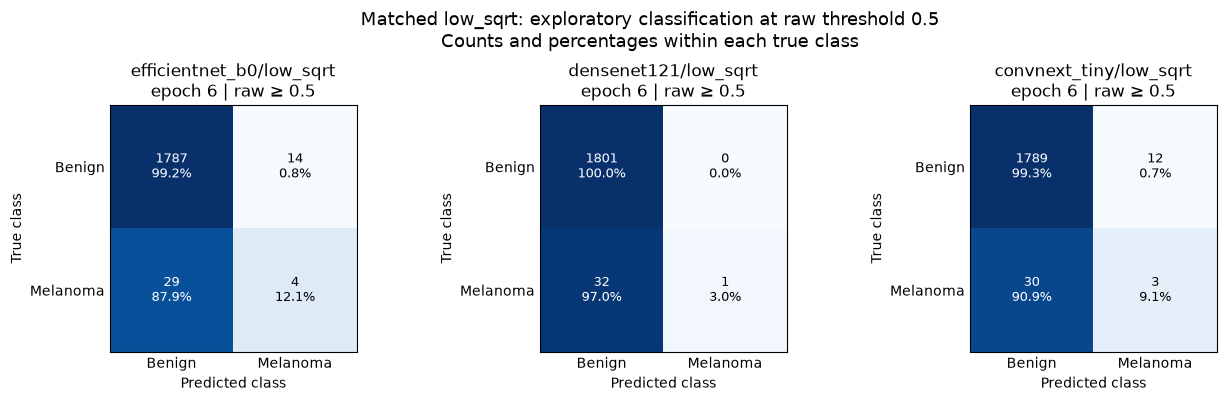

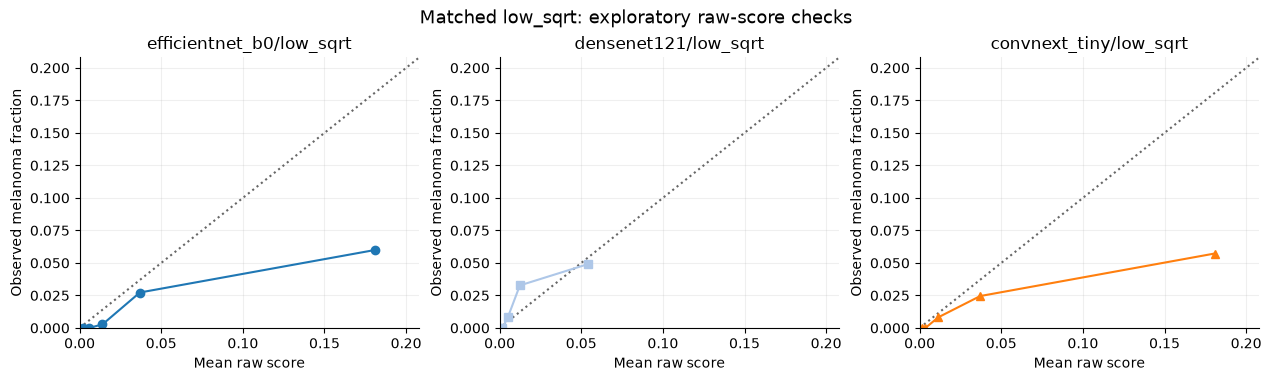

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.002074,0.000000,0.000285,0.003629,45,efficientnet_b0/low_sqrt
1,2,367,0,0.005793,0.000000,0.003631,0.008343,63,efficientnet_b0/low_sqrt
2,3,366,1,0.014004,0.002732,0.008363,0.021968,88,efficientnet_b0/low_sqrt
3,4,367,10,0.036893,0.027248,0.022069,0.058213,94,efficientnet_b0/low_sqrt
4,5,367,22,0.180943,0.059946,0.058433,0.836534,92,efficientnet_b0/low_sqrt
5,1,367,0,0.000693,0.000000,0.000140,0.001075,46,densenet121/low_sqrt
6,2,367,0,0.001751,0.000000,0.001078,0.002714,60,densenet121/low_sqrt
7,3,366,3,0.005025,0.008197,0.002723,0.008061,88,densenet121/low_sqrt
8,4,367,12,0.012382,0.032698,0.008063,0.018460,90,densenet121/low_sqrt
9,5,367,18,0.054014,0.049046,0.018573,0.507202,93,densenet121/low_sqrt


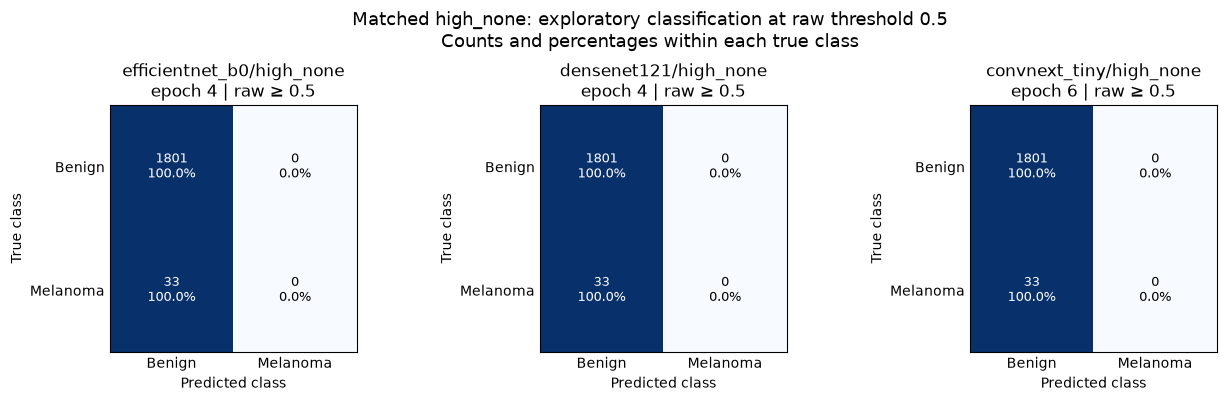

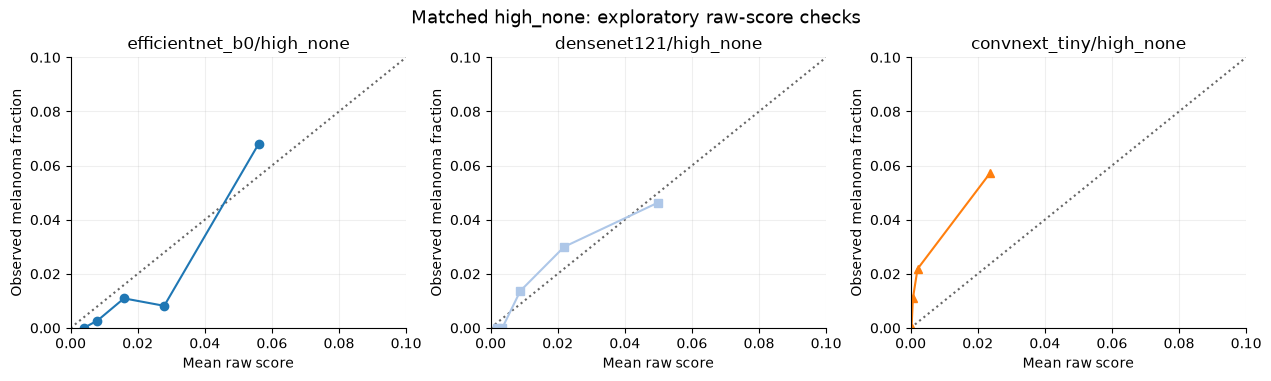

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.003893,0.000000,0.001476,0.005676,37,efficientnet_b0/high_none
1,2,367,1,0.008010,0.002725,0.005686,0.010791,68,efficientnet_b0/high_none
2,3,366,4,0.015912,0.010929,0.010804,0.021587,78,efficientnet_b0/high_none
3,4,367,3,0.027895,0.008174,0.021601,0.034557,87,efficientnet_b0/high_none
4,5,367,25,0.056087,0.068120,0.034652,0.220570,77,efficientnet_b0/high_none
5,1,367,0,0.001818,0.000000,0.001069,0.002343,35,densenet121/high_none
6,2,367,0,0.003480,0.000000,0.002349,0.005393,57,densenet121/high_none
7,3,366,5,0.008835,0.013661,0.005413,0.013466,89,densenet121/high_none
8,4,367,11,0.021913,0.029973,0.013554,0.031825,86,densenet121/high_none
9,5,367,17,0.049903,0.046322,0.031871,0.095705,76,densenet121/high_none


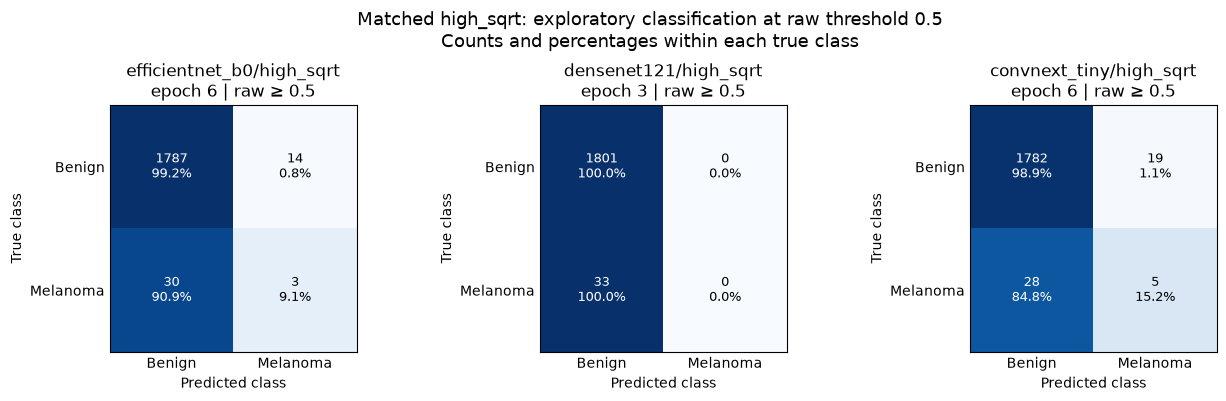

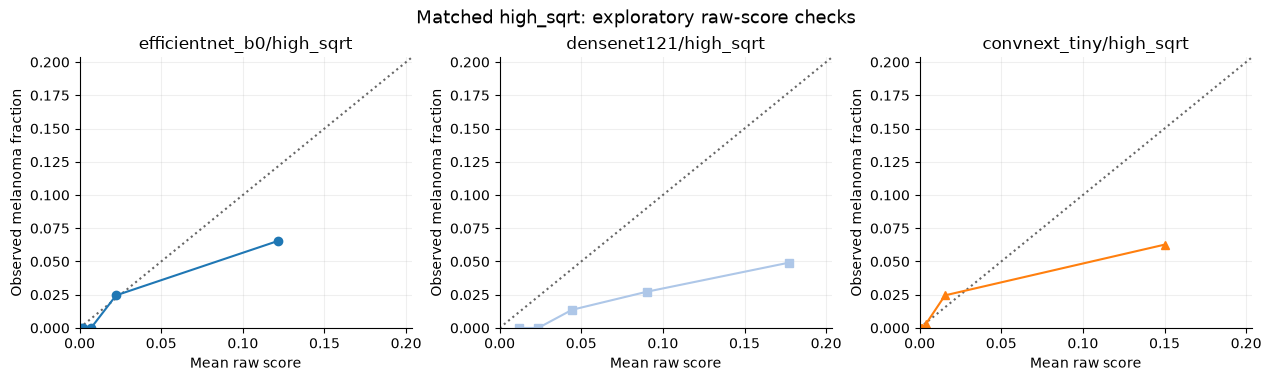

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.000941,0.000000,0.000233,0.001392,36,efficientnet_b0/high_sqrt
1,2,367,0,0.002102,0.000000,0.001397,0.003288,53,efficientnet_b0/high_sqrt
2,3,366,0,0.007013,0.000000,0.003289,0.012499,82,efficientnet_b0/high_sqrt
3,4,367,9,0.022358,0.024523,0.012525,0.034486,86,efficientnet_b0/high_sqrt
4,5,367,24,0.121412,0.065395,0.034642,0.806844,81,efficientnet_b0/high_sqrt
5,1,367,0,0.012146,0.000000,0.006575,0.016516,38,densenet121/high_sqrt
6,2,367,0,0.023614,0.000000,0.016544,0.030899,63,densenet121/high_sqrt
7,3,366,5,0.044378,0.013661,0.030916,0.062530,85,densenet121/high_sqrt
8,4,367,10,0.090198,0.027248,0.062672,0.126206,83,densenet121/high_sqrt
9,5,367,18,0.176982,0.049046,0.126215,0.259389,58,densenet121/high_sqrt


In [6]:
if matched:
    display(metrics[["pipeline_id", "selected_epoch", "threshold", "score_type", "TP", "FP", "TN", "FN",
        "precision", "recall", "sensitivity", "specificity", "f1"]].style.format(
        {name: "{:.4f}" for name in ["precision", "recall", "sensitivity", "specificity", "f1"]}, na_rep="Undefined"))
    for slot in summary["matched_recipe_slots"]:
        paired = {key: frame for key, frame in matched.items() if frame.recipe_slot.iloc[0] == slot}
        confusion = plot_confusion_matrices(paired, epochs=epochs,
            title=f"Matched {slot}: exploratory classification at raw threshold 0.5")
        save_figure(confusion, figures_dir / f"{slot}_confusion_threshold_0_5.png")
        plt.show()
        reliability, bins = plot_raw_reliability(paired, title=f"Matched {slot}: exploratory raw-score checks")
        save_figure(reliability, figures_dir / f"{slot}_raw_reliability.png")
        bins.to_csv(tables_dir / f"{slot}_reliability_support.csv", index=False)
        plt.show()
        display(bins)


## Unmatched executed records and next steps

Completed unmatched trials are saved below separately. They are not used to
rank families. Paused fits retain compatible model/optimiser/scheduler/scaler/RNG
states and resume at epoch boundaries; budget exhaustion supplies no evidence
against them. Finish paused comparisons before independently validating every
family with longer training and three inner folds.

Later stages test augmentation/preprocessing separately for each architecture
and repeat all selection inside five outer-training partitions. Short-pilot
results cannot globally prune candidates. Swin, final evaluation, uncertainty,
fusion and reserved-test evaluation remain outside this session.


In [7]:
unmatched = {key: frame for key, frame in predictions.items()
    if key in set(summary["unmatched_completed_trials"])}
if unmatched:
    unmatched_metrics = metric_table(unmatched, threshold=.5, epochs=epochs)
    unmatched_metrics.to_csv(tables_dir / "unmatched_exploratory_records.csv", index=False)
    display(unmatched_metrics)
else:
    print("Unmatched completed new trials: none.")
(run_dir / "reporting_receipt.json").write_text(json.dumps({
    "run_id": summary["run_id"], "training_enabled_in_notebook": TRAIN_ARCHITECTURES,
    "matched_recipe_slots": summary["matched_recipe_slots"], "threshold": .5,
    "threshold_tuned": False, "calibration_fitted": False, "test_loaded": False,
    "status": summary["status"],
    "trial_statuses": {record["pipeline_id"]: record["status"] for record in all_records},
    "reporting_source_sha256": {relative: sha256(PROJECT_ROOT / relative) for relative in [
        "src/melanoma_detection/image_evaluation.py", "src/melanoma_detection/image_reporting.py",
        "scripts/build_image_architecture_notebook.py"]},
    "summary_sha256": sha256(run_dir / "summary.json"),
    "prediction_csv_sha256": {str(Path(record["predictions_file"]).relative_to(PROJECT_ROOT)):
        sha256(record["predictions_file"]) for record in all_records
        if record.get("status") == "complete" and record.get("predictions_file")},
    "figures": sorted(path.name for path in figures_dir.glob("*.png"))}, indent=2), encoding="utf-8")
print("Artifacts:", run_dir)
print("Outer evaluation: not performed | reserved test: not loaded")


Unmatched completed new trials: none.
Artifacts: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\architecture_pilot_3h_v1
Outer evaluation: not performed | reserved test: not loaded


## Limitations

- Six epochs on one inner patient split measure early behaviour, not each family's full learning potential.
- Best recipes and epochs reuse validation labels. These are exploratory observations, not final outer performance.
- The fixed weak/unchanged profile controls this comparison; each architecture still requires independent augmentation/preprocessing selection later.
- Fitting objectives differ under weighting. Raw scores are uncalibrated and threshold 0.5 is not tuned.
- Paused/unmatched trials cannot lose a comparison, and short results cannot exclude slower families.
- Three-fold confirmation, calibration/threshold fitting, nested evaluation, uncertainty, fusion and the reserved test remain separate.


## Summary

The observations below come from executed saved predictions on matching patients.
They describe the six-epoch experiment; no final architecture winner is selected.


In [8]:
if matched:
    observed = metric_table(matched, threshold=.5, epochs=epochs)
    observed["architecture"] = observed.pipeline_id.str.split("/").str[0]
    family_best = observed.sort_values(["architecture", "average_precision", "selected_epoch", "pipeline_id"],
        ascending=[True, False, True, True]).groupby("architecture", sort=False).head(1)
    family_best = family_best.rename(columns={"pipeline_id": "observed_recipe", "selected_epoch": "best_epoch"})
    print("All eight new trials completed." if summary["comparison_complete"] else
        "Partial comparison: family observations use completed matching slots only.")
    display(family_best[["architecture", "observed_recipe", "best_epoch", "average_precision", "roc_auc"]])
    late = family_best.loc[family_best.best_epoch.ge(5), "architecture"].tolist()
    if late:
        display(Markdown("Best observed epochs are near the six-epoch cap for **" +
            ", ".join(late) + "**. Their late peaks support additional training; they do not establish optimal durations."))
else:
    print("No matching slot completed for all three families; there is no comparative family summary yet.")
if not summary["comparison_complete"]:
    outstanding = ledger.loc[ledger.status.ne("complete"),
        ["pipeline_id", "status", "completed_epochs", "selected_epoch"]]
    display(outstanding)
    display(Markdown("Finish missing or paused matching trials before expanding conclusions. "
        "Budget exhaustion is not evidence against unfinished candidates."))
display(Markdown("Next, independently validate **all three families** with their own recipes, "
    "a **30-epoch cap** and **three inner patient folds**. The cap is a maximum budget, "
    "distinct from the validation-selected best epoch. No longer training starts in this reporting notebook."))
print("No final architecture selected | outer evaluation: not performed | reserved test: not loaded")


All eight new trials completed.


,architecture,observed_recipe,best_epoch,average_precision,roc_auc
11,convnext_tiny,convnext_tiny/high_sqrt,6,0.149493,0.864183
4,densenet121,densenet121/low_none,2,0.145206,0.772971
1,efficientnet_b0,efficientnet_b0/low_sqrt,6,0.138318,0.866337


Best observed epochs are near the six-epoch cap for **convnext_tiny, efficientnet_b0**. Their late peaks support additional training; they do not establish optimal durations.

Next, independently validate **all three families** with their own recipes, a **30-epoch cap** and **three inner patient folds**. The cap is a maximum budget, distinct from the validation-selected best epoch. No longer training starts in this reporting notebook.

No final architecture selected | outer evaluation: not performed | reserved test: not loaded
